  Preparing metadata (setup.py) ... done
              0          1           2                 3             4   \
0         shrimp    almonds     avocado    vegetables mix  green grapes   
1        burgers  meatballs        eggs               NaN           NaN   
2        chutney        NaN         NaN               NaN           NaN   
3         turkey    avocado         NaN               NaN           NaN   
4  mineral water       milk  energy bar  whole wheat rice     green tea   

                 5     6               7             8             9   \
0  whole weat flour  yams  cottage cheese  energy drink  tomato juice   
1               NaN   NaN             NaN           NaN           NaN   
2               NaN   NaN             NaN           NaN           NaN   
3               NaN   NaN             NaN           NaN           NaN   
4               NaN   NaN             NaN           NaN           NaN   

               10         11     12     13             14      15  \


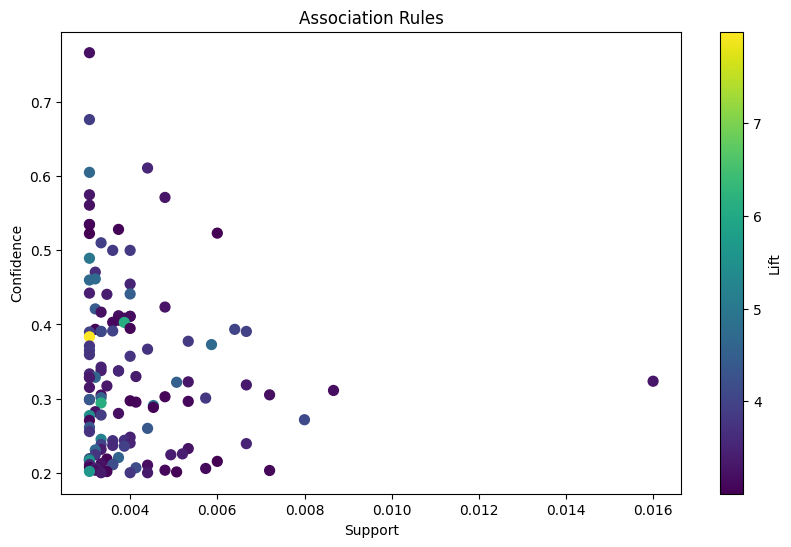

Minimum Confidence: 0.3   Number of Rules: 51
Minimum Confidence: 0.4   Number of Rules: 30
Minimum Confidence: 0.5   Number of Rules: 14
Minimum Confidence: 0.6   Number of Rules: 3
Minimum Confidence: 0.7   Number of Rules: 1


In [1]:
!pip install apyori -q

import pandas as pd
import matplotlib.pyplot as plt
from apyori import apriori

df = pd.read_csv("Market_Basket_Optimisation.csv", header=None)

print(df.head())
print("Shape:", df.shape)

transactions = []

for i in range(len(df)):
    transactions.append(
        [str(df.values[i, j]) for j in range(df.shape[1])
         if str(df.values[i, j]) != "nan"]
    )

rules = apriori(
    transactions,
    min_support=0.003,
    min_confidence=0.2,
    min_lift=3,
    min_length=2
)

rules = list(rules)

print("Number of rules:", len(rules))

result = []

for rule in rules:
    items = list(rule.items)
    for ordered_stat in rule.ordered_statistics:
        result.append([
            ", ".join(ordered_stat.items_base),
            ", ".join(ordered_stat.items_add),
            rule.support,
            ordered_stat.confidence,
            ordered_stat.lift
        ])

rules_df = pd.DataFrame(
    result,
    columns=["Antecedent", "Consequent", "Support", "Confidence", "Lift"]
)

rules_df = rules_df.sort_values(
    by="Confidence", ascending=False
).reset_index(drop=True)

print("\nAssociation Rules:")
print(rules_df.head(10))

plt.figure(figsize=(10,6))
plt.scatter(
    rules_df["Support"],
    rules_df["Confidence"],
    c=rules_df["Lift"],
    cmap="viridis",
    s=50
)
plt.colorbar(label="Lift")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Association Rules")
plt.show()

# Increasing minimum confidence
for confidence in [0.3, 0.4, 0.5, 0.6, 0.7]:
    r = list(apriori(
        transactions,
        min_support=0.003,
        min_confidence=confidence,
        min_lift=3,
        min_length=2
    ))
    print("Minimum Confidence:", confidence,
          "  Number of Rules:", len(r))
